# Yambda 05 · Tuning iALS properly

Starting point from `04`: **iALS(f=128, reg=0.05, alpha=10, half-life 7d), recall@10 = 0.0294**.
Two problems with that grid:
1. The best half-life (7 days) was the **smallest value we tried**, so the optimum may be shorter.
2. `regularization` was never tuned (Rendle et al. 2022: the most commonly neglected iALS knob).

Search strategy: one knob at a time, each step starting from the best so far
(coordinate search). Cheaper than a full grid, at the cost of missing some interactions
between knobs. All on the validation split; the test split stays untouched.

Runtime: ~1-2 min per model at f=128, ~3-4 min at f=256. About 15-20 min in total.

In [1]:
import json, time
import pandas as pd
import matplotlib.pyplot as plt
from musicrec import config
from musicrec.preprocess import Split
from musicrec.evaluation import evaluate
from musicrec.models.baselines import MostPopular
from musicrec.models.als import IALS

pd.set_option("display.float_format", "{:,.4f}".format)
split = Split.load(config.YAMBDA_SPLIT_VAL_DIR)
COLS = ["recall@10", "ndcg@10", "hit_rate@10", "recall@50", "coverage@10", "avg_pop@10", "fit_s"]

results, models, log = {}, {}, []
def run(model, step):
    t = time.time()
    model.fit(split)
    res = evaluate(model, split)
    res["fit_s"] = time.time() - t
    results[model.name], models[model.name] = res, model
    log.append({"step": step, "model": model.name, **model.params(), "recall@10": res["recall@10"]})
    print(f"[{step}] {model.name:<55} recall@10={res['recall@10']:.4f}  ({res['fit_s']:.0f}s)")
    return res["recall@10"]

def best_params():
    best = max(log, key=lambda r: r["recall@10"])
    return {k: best[k] for k in ["factors", "regularization", "alpha", "half_life_days"]}

pop = MostPopular(by="listeners", recent_days=7).fit(split)
BAR = evaluate(pop, split)["recall@10"]
print(f"bar to beat: {pop.name} recall@10={BAR:.4f}")

bar to beat: MostPopular(listeners, last 7d) recall@10=0.0235


## Step A · half-life, extended below 7 days

In [2]:
for hl in [1, 3, 5, 7]:
    run(IALS(factors=128, regularization=0.05, alpha=10, half_life_days=hl), "A half-life")
print("best so far:", best_params())

[A half-life] iALS(f=128, reg=0.05, alpha=10, half-life 1d)           recall@10=0.0294  (52s)
[A half-life] iALS(f=128, reg=0.05, alpha=10, half-life 3d)           recall@10=0.0303  (72s)
[A half-life] iALS(f=128, reg=0.05, alpha=10, half-life 5d)           recall@10=0.0295  (69s)
[A half-life] iALS(f=128, reg=0.05, alpha=10, half-life 7d)           recall@10=0.0294  (74s)
best so far: {'factors': 128, 'regularization': 0.05, 'alpha': 10, 'half_life_days': 3}


## Step B · regularization (log-spaced)

In [3]:
p = best_params()
for reg in [0.005, 0.5, 5.0]:
    run(IALS(**{**p, "regularization": reg}), "B regularization")
print("best so far:", best_params())

[B regularization] iALS(f=128, reg=0.005, alpha=10, half-life 3d)          recall@10=0.0302  (62s)
[B regularization] iALS(f=128, reg=0.5, alpha=10, half-life 3d)            recall@10=0.0302  (70s)
[B regularization] iALS(f=128, reg=5.0, alpha=10, half-life 3d)            recall@10=0.0311  (70s)
best so far: {'factors': 128, 'regularization': 5.0, 'alpha': 10, 'half_life_days': 3}


## Step C · alpha (confidence scale)

In [4]:
p = best_params()
for alpha in [3, 30]:
    run(IALS(**{**p, "alpha": alpha}), "C alpha")
print("best so far:", best_params())

[C alpha] iALS(f=128, reg=5.0, alpha=3, half-life 3d)             recall@10=0.0307  (72s)
[C alpha] iALS(f=128, reg=5.0, alpha=30, half-life 3d)            recall@10=0.0316  (77s)
best so far: {'factors': 128, 'regularization': 5.0, 'alpha': 30, 'half_life_days': 3}


## Step D · capacity

In [5]:
p = best_params()
run(IALS(**{**p, "factors": 256}), "D factors")
BEST = best_params()
print("final:", BEST)

[D factors] iALS(f=256, reg=5.0, alpha=30, half-life 3d)            recall@10=0.0331  (106s)
final: {'factors': 256, 'regularization': 5.0, 'alpha': 30, 'half_life_days': 3}


## Results

In [6]:
search = pd.DataFrame(log).sort_values("recall@10", ascending=False)
search

,step,model,factors,regularization,alpha,iterations,weighting,half_life_days,recall@10
9,D factors,"iALS(f=256, reg=5.0, alpha=30, half-life 3d)",256,5.0000,30,15,log,3,0.0331
8,C alpha,"iALS(f=128, reg=5.0, alpha=30, half-life 3d)",128,5.0000,30,15,log,3,0.0316
6,B regularization,"iALS(f=128, reg=5.0, alpha=10, half-life 3d)",128,5.0000,10,15,log,3,0.0311
7,C alpha,"iALS(f=128, reg=5.0, alpha=3, half-life 3d)",128,5.0000,3,15,log,3,0.0307
1,A half-life,"iALS(f=128, reg=0.05, alpha=10, half-life 3d)",128,0.0500,10,15,log,3,0.0303
4,B regularization,"iALS(f=128, reg=0.005, alpha=10, half-life 3d)",128,0.0050,10,15,log,3,0.0302
5,B regularization,"iALS(f=128, reg=0.5, alpha=10, half-life 3d)",128,0.5000,10,15,log,3,0.0302
2,A half-life,"iALS(f=128, reg=0.05, alpha=10, half-life 5d)",128,0.0500,10,15,log,5,0.0295
3,A half-life,"iALS(f=128, reg=0.05, alpha=10, half-life 7d)",128,0.0500,10,15,log,7,0.0294
0,A half-life,"iALS(f=128, reg=0.05, alpha=10, half-life 1d)",128,0.0500,10,15,log,1,0.0294


In [7]:
best_name = IALS(**BEST).name
summary = pd.DataFrame({pop.name: evaluate(pop, split), best_name: results[best_name]}).T[COLS[:-1]]
summary.loc["relative gain"] = summary.iloc[1] / summary.iloc[0] - 1
summary

,recall@10,ndcg@10,hit_rate@10,recall@50,coverage@10,avg_pop@10
"MostPopular(listeners, last 7d)",0.0235,0.0224,0.1062,0.0428,0.0007,"1,819.4269"
"iALS(f=256, reg=5.0, alpha=30, half-life 3d)",0.0331,0.0295,0.1620,0.0655,0.0526,846.7759
relative gain,0.4081,0.3194,0.5257,0.5299,79.4667,-0.5346


In [8]:
# Secondary target (organic + recommended discoveries), same as in 04
targets_all = pd.read_parquet(config.YAMBDA_SPLIT_VAL_DIR / "targets_all.parquet")
pd.DataFrame({n: evaluate(m, split, targets=targets_all)
              for n, m in [(pop.name, pop), (best_name, models[best_name])]}).T[["recall@10", "ndcg@10", "hit_rate@10"]]

,recall@10,ndcg@10,hit_rate@10
"MostPopular(listeners, last 7d)",0.0391,0.0401,0.2036
"iALS(f=256, reg=5.0, alpha=30, half-life 3d)",0.0806,0.0794,0.3923


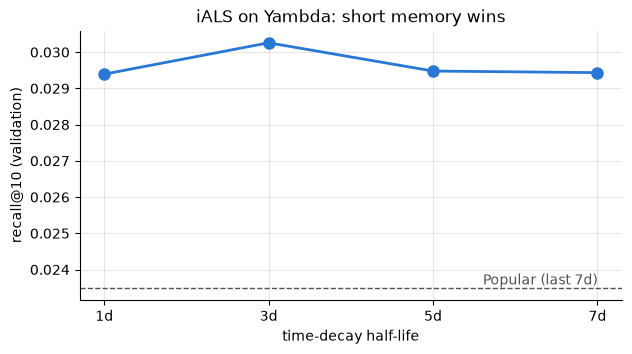

In [9]:
# Half-life curve at the final settings (reuses step A runs where possible)
BLUE, GRAY = "#2a78d6", "#52514e"
a = pd.DataFrame(log).query("step == 'A half-life'")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(a["half_life_days"].astype(str) + "d", a["recall@10"], color=BLUE, lw=2, marker="o", markersize=8)
ax.axhline(BAR, color=GRAY, lw=1, ls="--")
ax.text(len(a) - 1, BAR, "  Popular (last 7d)", va="bottom", ha="right", color=GRAY)
ax.set(xlabel="time-decay half-life", ylabel="recall@10 (validation)", title="iALS on Yambda: short memory wins")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
fig.savefig(config.YAMBDA_FIGURES_DIR / "y05_ials_half_life.png", dpi=150, bbox_inches="tight")

In [10]:
# Save the winner: later stages (PyTorch models, final test run) read it from here
out = config.PROJECT_ROOT / "reports" / "yambda"
out.mkdir(parents=True, exist_ok=True)
search.to_csv(out / "ials_tuning.csv", index=False)
(out / "best_ials.json").write_text(json.dumps({"params": IALS(**BEST).params(),
                                                "val_recall@10": results[best_name]["recall@10"]}, indent=2))
print((out / "best_ials.json").read_text())

{
  "params": {
    "factors": 256,
    "regularization": 5.0,
    "alpha": 30,
    "iterations": 15,
    "weighting": "log",
    "half_life_days": 3
  },
  "val_recall@10": 0.03308292378827779
}
